# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


In [2]:
df.head()

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area,Density,World share (%)
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,0.00


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose line chart. The question is about change over time and a line can show a trend very well among different years. I set the population of each continent in 1970 equal 100 so all lines start from a common point and compare the growth speed not the size. If I did not do this Asia would be above the all continents. Africa is orange because it is the answer of question and all others are gray to be just a background. Instead of legend I wrote the names just beside the lines and gave the Europe a label because it had the least growth.

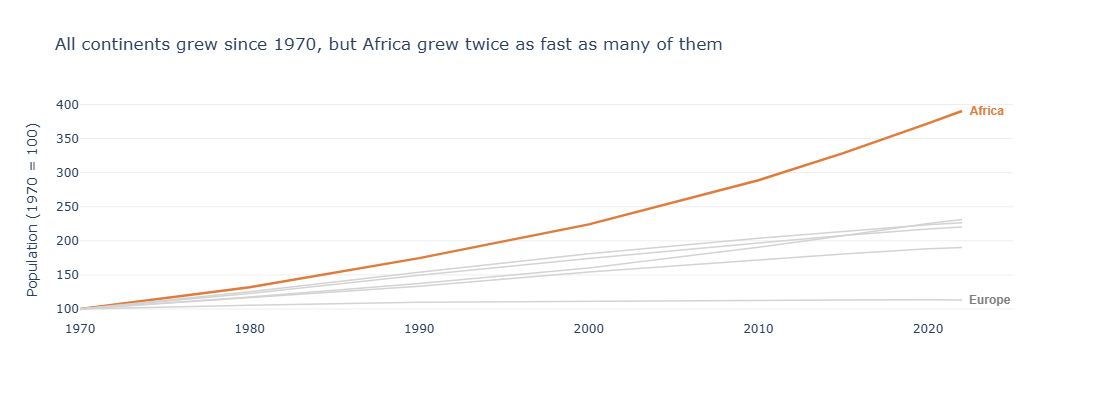

In [34]:
# Q1

cont = df_long.groupby(['Continent', 'Year'])['Population'].sum().reset_index()
cont['Growth'] = cont['Population'] / cont.groupby('Continent')['Population'].transform('first') * 100

highlight = 'Africa'
color_map = {c: '#E07B39' if c == highlight else 'lightgrey' for c in cont['Continent'].unique()}

fig = px.line(cont, x='Year', y='Growth', color='Continent',
              color_discrete_map=color_map,
              labels={'Growth': 'Population (1970 = 100)', 'Year': ''},
              title='All continents grew since 1970, but Africa grew twice as fast as many of them',
              template='plotly_white',
              height=400
              )

fig.update_traces(
    line=dict(width=1.5),   
    showlegend=False      
)

fig.update_traces(
    line=dict(width=2.5),
    selector=dict(name=highlight)
)

highlight_label = cont.loc[(cont['Continent'] == highlight) & (cont['Year'] == cont['Year'].max())]

others_label = cont.loc[(cont['Continent'] == 'Europe') & (cont['Year'] == cont['Year'].max())]

fig.add_annotation(
    x=highlight_label['Year'].values[0], y=highlight_label['Growth'].values[0],
    text=highlight, showarrow=False,
    xanchor='left', xshift=5,
    font=dict(color='#E07B39', size=12, weight='bold', family='Arial')
)

fig.add_annotation(
    x=others_label['Year'].values[0], y=others_label['Growth'].values[0],
    text='Europe', showarrow=False,
    xanchor='left', xshift=5,
    font=dict(color='grey', size=12, weight='bold', family='Arial')
)

fig.update_layout(
    yaxis=dict(gridcolor='#EEEEEE'),
    xaxis=dict(showgrid=False)
)

fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a sorted horizontal bar chart. The question is about ranking, and with sorted bars we can read the order very quickly. I made it horizontal because the country names are too long and horizontaly they are easy to read. The axis starts from zero. The African countries are red and all others are grey, because the question is about Africa so we make it colorful, so we can count the 4 red bars with one look. Instead of a legend, I added a small box that says red is for Africa.


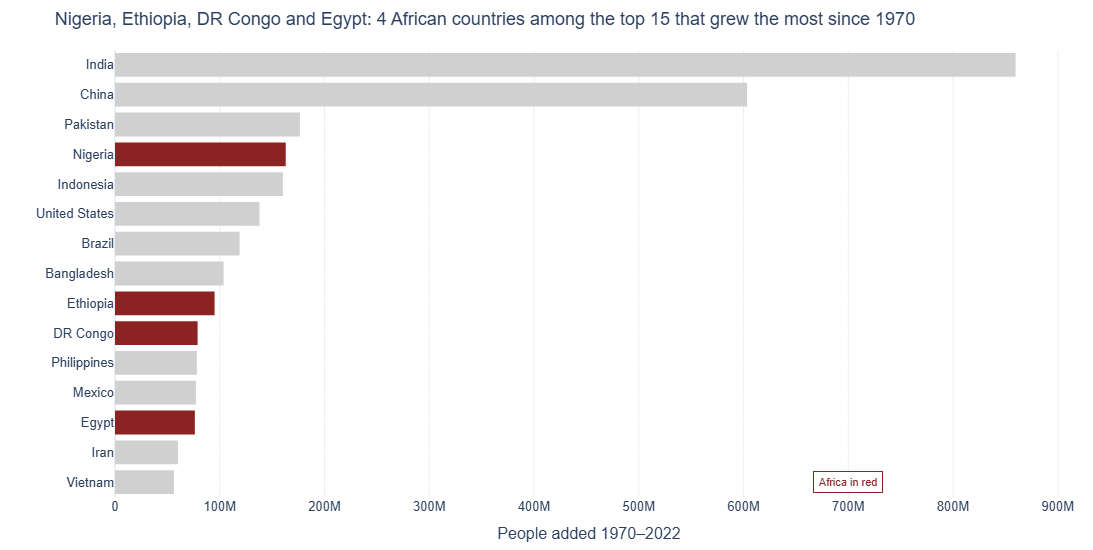

In [33]:
# Q2
df['Added'] = df['2022 Population'] - df['1970 Population']

top15 = df.nlargest(15, 'Added').sort_values('Added')
top15 = top15.copy()
top15['highlight'] = top15['Continent'].apply(
    lambda r: 'Africa' if r == 'Africa' else 'Other'
)
fig = px.bar(
    top15,
    x='Added', y='Country',
    orientation='h',
    color='highlight',
    color_discrete_map={
        'Africa': '#8b2323',  
        'Other':  '#D0D0D0' 
    },
    category_orders={'Country': top15.sort_values('Added', ascending=False)['Country'].tolist()},
    title='Nigeria, Ethiopia, DR Congo and Egypt: 4 African countries among the top 15 that grew the most since 1970',
    labels={'Added': 'People added 1970–2022', 'Country': '', 'highlight': ''},
    template='plotly_white',
    height=550
)
fig.update_traces(marker_line_width=0)

fig.update_layout(
    xaxis=dict(gridcolor='#EEEEEE'),
    yaxis=dict(gridcolor='white'),
    font=dict(family='Arial', size=13),
    margin=dict(l=10, r=30, t=50, b=40),
    showlegend=False
)
fig.add_annotation(
    x=700000000, y='Vietnam',
    text='Africa in red',
    showarrow=False,
    font=dict(color='#8b2323', size=11),
    bgcolor='white', bordercolor='#8b2323', borderwidth=1, borderpad=4
)

fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a scatter plot. The question is about the relationship between two numbers, area and population, and a scatter plot shows this very well. Both axes are on log scale, because the numbers are very skewed (from a few hundred people to 1.4 billion) and without log all the points would be in one corner. The colours show the continents, because the question asks if the pattern is different between continents. I used the Safe palette, which is safe for colour-blind people. I labelled Bangladesh and Greenland directly, because they look unusual rather than the other countries: Bangladesh has a lot of people for its size and Greenland has very few.

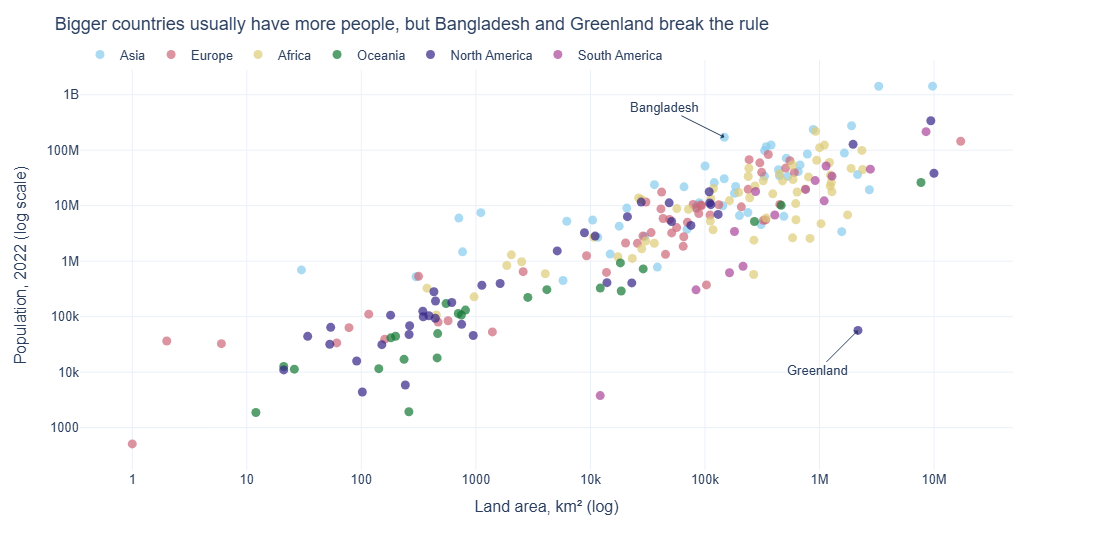

In [18]:
# Q3
import math

fig = px.scatter(
    data_frame=df, x='Area', y='2022 Population',
    color='Continent',
    hover_name='Country',
    hover_data={'Continent': False},
    log_x=True,                             
    log_y=True,                             
    labels={'Area': 'Land area, km² (log)',
            '2022 Population': 'Population, 2022 (log scale)',
            'Continent': ''},
    color_discrete_sequence=px.colors.qualitative.Safe,   
    template='plotly_white'
)
fig.update_layout(
    title='Bigger countries usually have more people, but Bangladesh and Greenland break the rule',
    font=dict(family='Arial', size=13),
    legend=dict(orientation='h', x=0, y=1.05, title=''),
    height=550
)
fig.update_traces(marker=dict(size=9, opacity=0.7))

for country, ax, ay in [('Bangladesh', -60, -30), ('Greenland', -40, 40)]:
    row = df[df['Country'] == country].iloc[0]
    fig.add_annotation(
        x=math.log10(row['Area']), y=math.log10(row['2022 Population']),
        text=f'{country}',
        showarrow=True, arrowhead=1, ax=ax, ay=ay,
        font=dict(size=13, family='Arial')
    )

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a box plot. The question asks about the spread, not only the average, and a box plot shows the median, the middle range and the outliers for each continent. I made it horizontal and sorted the continents by median. I removed the top 5% of values, because places like Macau and Monaco are so crowded that the boxes become too small to read, and I wrote this under the chart. South America is orange because it is the least crowded, and the other continents are grey.

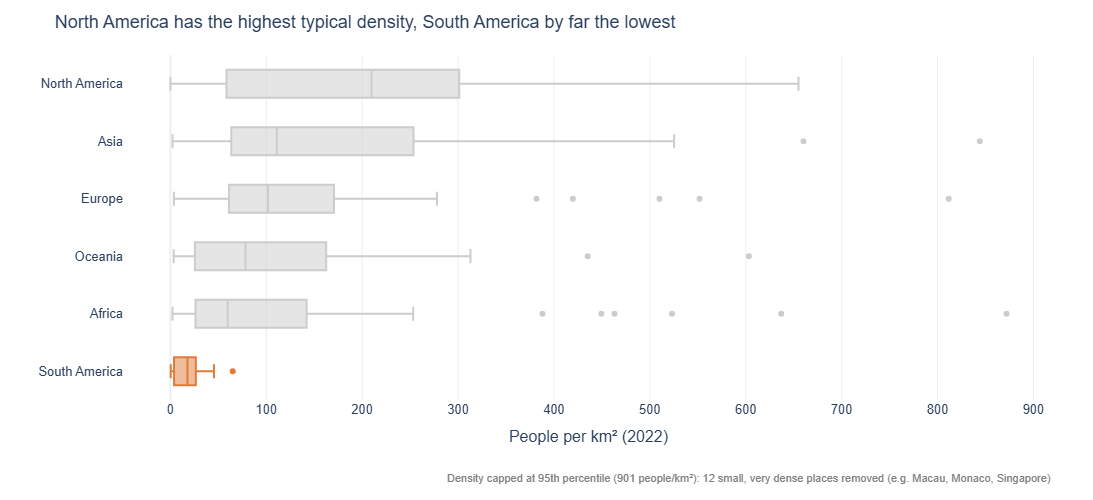

In [24]:
# Q4
p95 = df['Density'].quantile(0.95)
df_cap = df.loc[df['Density'] <= p95].copy()

med_order = df_cap.groupby('Continent')['Density'].median().sort_values(ascending=False).index.tolist()

fig = px.box(
    data_frame=df_cap,
    y='Continent', x='Density',
    color='Continent',
    orientation='h',
    points='outliers',            
    category_orders={'Continent': med_order},
    color_discrete_sequence=['#CCCCCC']*len(med_order),   
    labels={'Density': 'People per km² (2022)', 'Continent': ''},
    template='plotly_white',
    height=500
)

for trace in fig.data:
    if trace.name == 'South America':
        trace.line.color = '#E07B39'
        trace.fillcolor = 'rgba(224, 123, 57, 0.5)'
        trace.marker.color = '#E07B39'

fig.add_annotation(
    text=f'Density capped at 95th percentile ({p95:.0f} people/km²): 12 small, very dense places removed (e.g. Macau, Monaco, Singapore)',
    xref='paper', yref='paper', x=1, y=-0.25,
    showarrow=False, xanchor='right',
    font=dict(color='grey', size=11)
)

fig.update_layout(
    title='North America has the highest typical density, South America by far the lowest',
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE'),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(l=60, r=40, t=55, b=100)
)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a choropleth map because the question asks where in the world the countries are. The colours go from red to blue, with white at zero: blue means the population grew and red means it shrank. Red and blue are safe for colour-blind people. You can see that most red countries are in Eastern Europe. I set the scale from -40% to +40%, because a few countries like Qatar grew more than 300% and made the rest of the map look white.

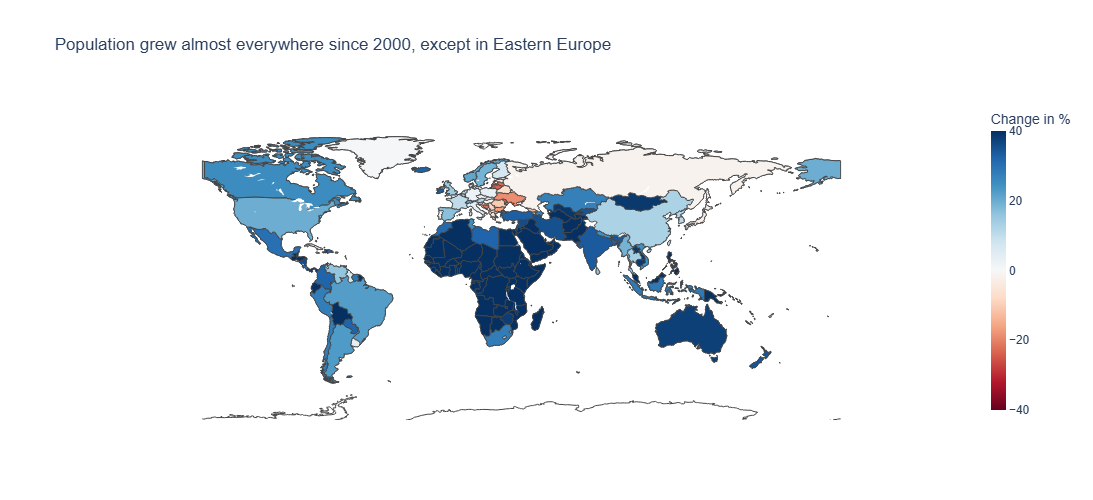

In [37]:
# Q5
df['Change_pct'] = (df['2022 Population'] - df['2000 Population']) / df['2000 Population'] * 100   

fig = px.choropleth(
    df,
    locations='CCA3',
    locationmode='ISO-3',
    color='Change_pct',
    color_continuous_scale='RdBu',          
    color_continuous_midpoint=0,
    range_color=[-40, 40],                  
    hover_name='Country',
    hover_data={'Change_pct': ':.1f', '2000 Population': ':,', '2022 Population': ':,', 'CCA3': False},
    labels={'Change_pct': 'Population change 2000–2022 (%)'},
    title='Population grew almost everywhere since 2000, except in Eastern Europe',
    template='plotly_white',
    height=500, width=1000
)
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False),
    coloraxis_colorbar=dict(title='Change in %', thickness=15, len=1),
)
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a treemap. The question asks to show the population at two levels, continents and countries, in one chart, and a treemap is suitable for this kind of nested data. The size of each box is the population, so with one look you can see where most people live. Asia is orange because more than half of the world lives there, and the other continents are grey. On each box I wrote the population and its share: for continents the share of the world, and for countries the share of their continent.

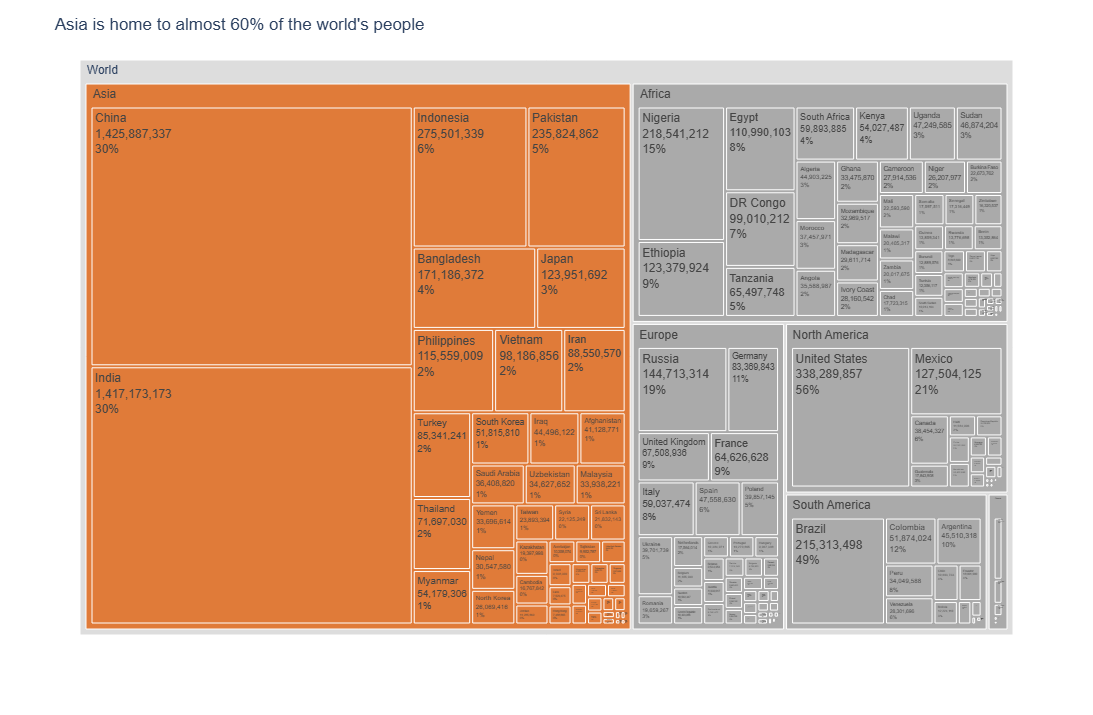

In [29]:
# Q6
color_discrete_mapping = {c: ('#E07B39' if c == 'Asia' else '#AAAAAA') for c in df['Continent'].unique()}

fig = px.treemap(
    df,
    path=[px.Constant('World'), 'Continent', 'Country'],
    values='2022 Population',          
    color='Continent',
    color_discrete_map=color_discrete_mapping,
    labels={'2022 Population': 'Population 2022'},
    height=700, width=1100,
    template='plotly_white'
)

fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f}<br>%{percentParent:.0%}',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentParent:.1%} of %{parent}<extra></extra>',
    root_color='white',
)

fig.update_layout(
    title='Asia is home to almost 60% of the world\'s people',
    font=dict(family='Arial', size=12),
)

fig.data[0].marker.colors = [
    c if c in color_discrete_mapping.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a 100% stacked bar chart because the question is about shares, and each bar adds up to 100%. There is one bar per year. Africa is orange and Europe is blue, because their shares changed the most, and blue and orange are safe for colour-blind people. Asia and the rest of the world are grey. I only wrote the numbers on Africa and Europe to keep the chart clean. Africa's share almost doubled and Europe's almost halved.

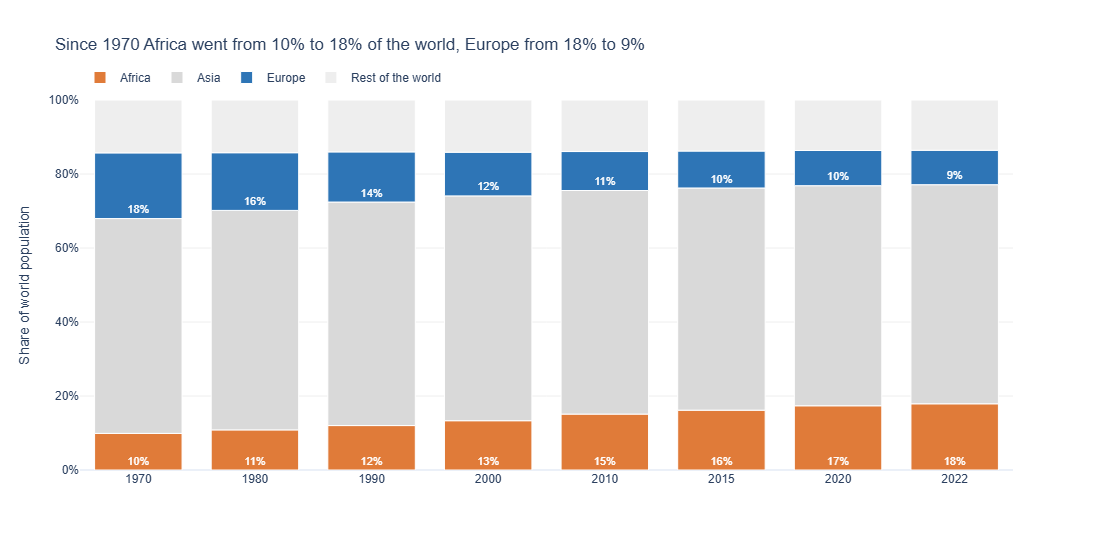

In [39]:
# Q7

df_long['Group'] = np.where(df_long['Continent'].isin(['Africa', 'Asia', 'Europe']),
                            df_long['Continent'], 'Rest of the world')

mix = df_long.groupby(['Year', 'Group'])['Population'].sum().reset_index()
mix['Share'] = mix['Population'] / mix.groupby('Year')['Population'].transform('sum')   

mix['Label'] = np.where(mix['Group'].isin(['Africa', 'Europe']), mix['Share'].map('{:.0%}'.format), '')

accent_mapping = {
    'Africa':            '#E07B39',   
    'Europe':            '#2E75B6',   
    'Asia':              '#D9D9D9',   
    'Rest of the world': '#EEEEEE',   
}

fig = px.bar(
    data_frame=mix,
    x='Year', y='Share',
    color='Group',
    text='Label',                                      
    color_discrete_map=accent_mapping,
    category_orders={'Group': ['Africa', 'Asia', 'Europe', 'Rest of the world']},   
    labels={'Share': 'Share of world population', 'Group': '', 'Year': ''},
    hover_data={'Label': False, 'Share': ':.2f'},
    height=550, width=1000,
    template='plotly_white',
)
fig.update_traces(
    textposition='inside', insidetextanchor='start',
    textfont=dict(color='white', size=11),
    marker_line_color='white', marker_line_width=1,    
)

fig.update_layout(
    title=dict(text="Since 1970 Africa went from 10% to 18% of the world, Europe from 18% to 9%"),
    font=dict(family='Arial', size=12),
    bargap=0.25,
    legend=dict(orientation='h', x=0, y=1.1),
    margin=dict(t=100),
    xaxis=dict(type='category'),
    yaxis=dict(tickformat='.0%', range=[0, 1], gridcolor='#EEEEEE'),
)

fig.show()